# 9. Time stepping and stability regions

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/spectral-methods-in-python/blob/main/notebooks/09_time_stepping_and_stability.ipynb)

*Companion to Chapter 10 of L. N. Trefethen, Spectral Methods in MATLAB (SIAM, 2000).*

A time-dependent partial differential equation is usually solved by discretizing space first
and marching forward in time with a formula for ordinary differential equations. The space
discretization of this course is extremely accurate. This notebook is about the price: the
spectral matrices have very large eigenvalues, and those eigenvalues, not accuracy, often
decide how small the time step must be.

- the method of lines, and the rule that connects eigenvalues, time step and stability
- stability regions of eight common time-stepping formulas, computed from scratch
- the eigenvalues of the Fourier and Chebyshev differentiation matrices
- time step limits from $O(N^{-1})$ to $O(N^{-4})$, and when an implicit formula pays

**Worked examples:** a pattern carried round a ring, the cooling of a slab with explicit and
implicit time stepping, and a pulse on a cable crossing a heavier section.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import lu_factor, lu_solve
from scipy.optimize import brentq

plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2, "figure.figsize": (6.4, 4),
})
BLUE, ORANGE, GREEN = "#2a78d6", "#eb6834", "#1baf7a"

In [2]:
# cheb(N) from notebook 5
def cheb(N):
    """Chebyshev differentiation matrix D, (N+1) x (N+1), and the points x_j = cos(jπ/N)."""
    if N == 0:
        return np.zeros((1, 1)), np.ones(1)
    j = np.arange(N + 1)
    x = np.cos(np.pi * j / N)
    c = np.where((j == 0) | (j == N), 2.0, 1.0) * (-1.0) ** j
    dx = x[:, None] - x[None, :]
    D = (c[:, None] / c[None, :]) / (dx + np.eye(N + 1))
    D -= np.diag(D.sum(axis=1))
    return D, x

# fourier_diff_matrix(N), fourier_diff2_matrix(N) and fft_derivative(v, order) from notebook 2
def fourier_diff_matrix(N):
    """First-derivative matrix for the periodic grid of N points (N even)."""
    if N % 2:
        raise ValueError("N must be even")
    h = 2 * np.pi / N
    k = np.arange(N)[:, None] - np.arange(N)[None, :]
    D = np.zeros((N, N))
    off = k != 0
    D[off] = 0.5 * (-1.0) ** k[off] / np.tan(k[off] * h / 2)
    return D

def fourier_diff2_matrix(N):
    """Second-derivative matrix for the periodic grid of N points (N even)."""
    if N % 2:
        raise ValueError("N must be even")
    h = 2 * np.pi / N
    k = np.arange(N)[:, None] - np.arange(N)[None, :]
    D2 = np.full((N, N), -np.pi**2 / (3 * h**2) - 1 / 6)
    off = k != 0
    D2[off] = -0.5 * (-1.0) ** k[off] / np.sin(k[off] * h / 2) ** 2
    return D2

def fft_derivative(v, order=1):
    """Spectral derivative of real periodic samples v; the Nyquist mode is zeroed for odd orders."""
    N = len(v)
    k = np.fft.fftfreq(N, d=1 / N)
    factor = (1j * k) ** order
    if order % 2 and N % 2 == 0:
        factor[N // 2] = 0
    return np.real(np.fft.ifft(factor * np.fft.fft(v)))

## 9.1 The method of lines and the rule of thumb

Take the heat equation $u_t = u_{xx}$. Replace the space derivative by a differentiation
matrix and the partial differential equation becomes a system of ordinary differential
equations for the grid values, one for each grid point:

$$\frac{d\mathbf{u}}{dt} = L_N\,\mathbf{u} .$$

This is the **method of lines**. Any formula for ordinary differential equations can now
advance $\mathbf{u}$ from $t_n$ to $t_{n+1} = t_n + \Delta t$.

**By hand.** To see when this goes wrong, write $\mathbf{u}$ as a combination of eigenvectors of
$L_N$. Each coefficient obeys the scalar equation $u' = \lambda u$ with $\lambda$ an eigenvalue.
Apply the forward Euler formula to it:

$$u^{n+1} = u^n + \Delta t\,\lambda u^n = (1 + z)\,u^n,\qquad z = \lambda\,\Delta t .$$

The numerical solution is multiplied by $1 + z$ at every step. It stays bounded when
$|1 + z| \le 1$, a disk of radius 1 centred at $z = -1$. This set is the **stability region**
of forward Euler. Every formula has one.

**Rule of thumb.** The method of lines is stable when $\lambda\,\Delta t$ lies in the stability
region of the time-stepping formula **for every eigenvalue** $\lambda$ of $L_N$.

The modes that decide are the ones with the largest $|\lambda|$. Notebook 8 showed that for a
spectral matrix those are artefacts of the grid with no physical meaning. They must be kept
stable all the same, or they grow from rounding errors and swamp the solution.

## 9.2 Stability regions

**One-step formulas.** Applied to $u' = \lambda u$, a one-step formula gives
$u^{n+1} = R(z)\,u^n$, and the stability region is $|R(z)| \le 1$.

| Formula | $R(z)$ |
| --- | --- |
| forward Euler | $1 + z$ |
| midpoint Runge-Kutta (2 stages) | $1 + z + \tfrac12 z^2$ |
| classical Runge-Kutta (RK4) | $1 + z + \tfrac12 z^2 + \tfrac16 z^3 + \tfrac1{24} z^4$ |
| backward Euler, $u^{n+1} = u^n + \Delta t\,\lambda u^{n+1}$ | $1/(1 - z)$ |
| trapezoidal rule, $u^{n+1} = u^n + \tfrac12\Delta t\,\lambda\,(u^n + u^{n+1})$ | $(1 + \tfrac12 z)/(1 - \tfrac12 z)$ |

The explicit Runge-Kutta polynomials are the Taylor series of $e^z$, the exact growth factor,
cut off at the order of the formula.

In [3]:
R = {
    "forward Euler": lambda z: 1 + z,
    "midpoint RK2": lambda z: 1 + z + z**2 / 2,
    "RK4": lambda z: 1 + z + z**2 / 2 + z**3 / 6 + z**4 / 24,
    "backward Euler": lambda z: 1 / (1 - z),
    "trapezoidal rule": lambda z: (1 + z / 2) / (1 - z / 2),
}

def axis_limit(R_of_z, direction):
    """Distance from the origin to the edge of the stability region along the given direction."""
    return brentq(lambda s: abs(R_of_z(s * direction)) - 1, 0.5, 10)

rk4_real, rk4_imag = axis_limit(R["RK4"], -1), axis_limit(R["RK4"], 1j)
print(f"RK4:  stable for real z down to -{rk4_real:.4f}, and for imaginary z up to ±{rk4_imag:.4f} i")
print(f"forward Euler and RK2:  real z down to -{axis_limit(R['forward Euler'], -1):.1f} and -{axis_limit(R['midpoint RK2'], -1):.1f}")
print(f"on the imaginary axis at z = 0.5i:  |R| = {abs(R['forward Euler'](0.5j)):.3f} (Euler), {abs(R['midpoint RK2'](0.5j)):.4f} (RK2), {abs(R['RK4'](0.5j)):.6f} (RK4)")

RK4:  stable for real z down to -2.7853, and for imaginary z up to ±2.8284 i
forward Euler and RK2:  real z down to -2.0 and -2.0
on the imaginary axis at z = 0.5i:  |R| = 1.118 (Euler), 1.0078 (RK2), 0.999895 (RK4)


**Multistep formulas** use several old values. The second-order Adams-Bashforth formula (AB2) is

$$u^{n+1} = u^n + \Delta t\,\big(\tfrac32 f^n - \tfrac12 f^{n-1}\big),\qquad f = \lambda u .$$

**By hand.** Look for solutions $u^n = \zeta^n$. Substituting and dividing by $\zeta^{n-1}$ gives
$\zeta^2 - \zeta = z\,(\tfrac32\zeta - \tfrac12)$. The formula is stable when both roots $\zeta$
have modulus at most 1. On the boundary of the stability region one root has modulus exactly
1, so $\zeta = e^{i\theta}$. Solve for $z$ instead of $\zeta$:

$$z(\theta) = \frac{\zeta^2 - \zeta}{\tfrac32\zeta - \tfrac12},\qquad \zeta = e^{i\theta},\quad 0 \le \theta \le 2\pi .$$

Tracing this curve is the **boundary-locus method**. The same recipe gives

- AB3: $z = \dfrac{\zeta^3 - \zeta^2}{(23\zeta^2 - 16\zeta + 5)/12}$;
- leapfrog, $u^{n+1} = u^{n-1} + 2\Delta t\,f^n$: $z = \dfrac{\zeta^2 - 1}{2\zeta} = i\sin\theta$.

The leapfrog locus is not a closed curve with an inside: it is the segment of the imaginary
axis between $-i$ and $i$, and that segment is the whole stability region.

In [4]:
zeta = np.exp(1j * np.linspace(0, 2 * np.pi, 1441))
locus = {
    "AB2": (zeta**2 - zeta) / ((3 * zeta - 1) / 2),
    "AB3": (zeta**3 - zeta**2) / ((23 * zeta**2 - 16 * zeta + 5) / 12),
    "leapfrog": (zeta**2 - 1) / (2 * zeta),
}
# coefficients (highest power first) of the two sides: left(ζ) = z right(ζ)
multistep = {
    "AB2": ([1, -1, 0], [0, 3 / 2, -1 / 2]),
    "AB3": ([1, -1, 0, 0], [0, 23 / 12, -16 / 12, 5 / 12]),
    "leapfrog": ([1, 0, -1], [0, 2, 0]),
}

def multistep_stable(name, z):
    """Root test: True if all roots ζ of left(ζ) - z right(ζ) have modulus at most 1."""
    left, right = multistep[name]
    return np.abs(np.roots(np.array(left, dtype=complex) - z * np.array(right))).max() <= 1 + 1e-9

**Verify** the key numbers, each from the computation above, and check the boundary-locus
curves against the direct root test at points on either side of them.

In [5]:
assert abs(rk4_real - 2.785) < 1e-3 and abs(rk4_imag - 2 * np.sqrt(2)) < 1e-9          # 2.785 and 2.828
assert abs(axis_limit(R["forward Euler"], -1) - 2) < 1e-9 and abs(axis_limit(R["midpoint RK2"], -1) - 2) < 1e-9
assert abs(R["forward Euler"](0.5j)) > 1 and abs(R["midpoint RK2"](0.5j)) > 1 > abs(R["RK4"](0.5j))
assert abs(locus["AB2"].real.min() + 1) < 1e-12 and abs(locus["AB3"].real.min() + 6 / 11) < 1e-12
assert np.abs(locus["leapfrog"].real).max() < 1e-12 and abs(locus["leapfrog"].imag.max() - 1) < 1e-12
assert multistep_stable("AB2", -0.95) and not multistep_stable("AB2", -1.05)
assert multistep_stable("AB3", -0.5) and not multistep_stable("AB3", -0.6)
assert multistep_stable("leapfrog", 0.95j) and not multistep_stable("leapfrog", 1.05j) and not multistep_stable("leapfrog", -0.05)
assert abs(R["backward Euler"](-1e6)) < 1e-5 and abs(abs(R["trapezoidal rule"](-1e6)) - 1) < 1e-5
ab3_imag = np.abs(locus["AB3"].imag[np.abs(locus["AB3"].real) < 2e-3]).max()
print(f"AB2 reaches {locus['AB2'].real.min():.3f} on the real axis, AB3 reaches {locus['AB3'].real.min():.4f} and ±{ab3_imag:.2f} i")

AB2 reaches -1.000 on the real axis, AB3 reaches -0.5455 and ±0.72 i


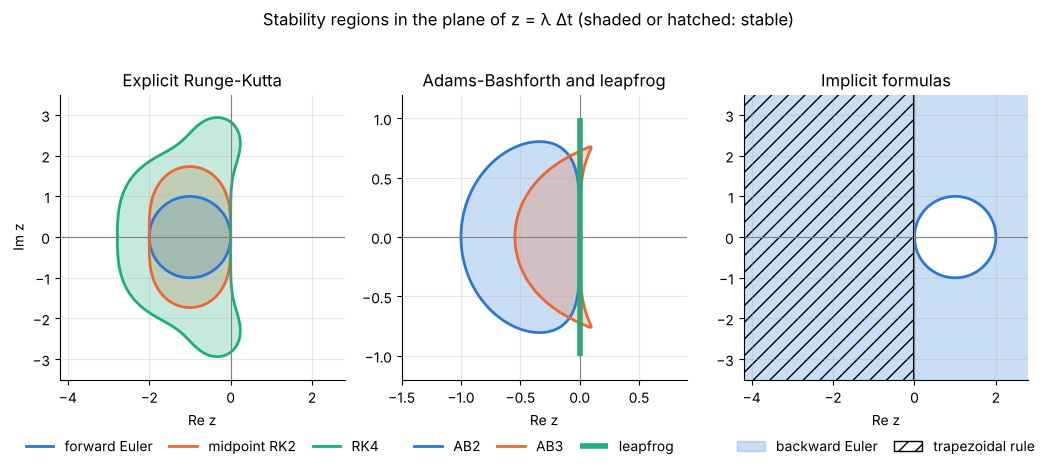

In [6]:
re, im = np.linspace(-4.2, 2.8, 280), np.linspace(-3.5, 3.5, 280)       # an even count keeps the poles z = 1, 2 off the grid
Z = re[None, :] + 1j * im[:, None]
fig, axes = plt.subplots(1, 3, figsize=(12.5, 4.7))

for name, colour in zip(("forward Euler", "midpoint RK2", "RK4"), (BLUE, ORANGE, GREEN)):
    axes[0].contourf(re, im, np.abs(R[name](Z)), levels=[0, 1], colors=[colour], alpha=0.25)
    axes[0].contour(re, im, np.abs(R[name](Z)), levels=[1], colors=[colour], linewidths=2)
    axes[0].plot([], [], color=colour, label=name)
axes[0].set(title="Explicit Runge-Kutta", xlim=(-4.2, 2.8), ylim=(-3.5, 3.5), ylabel="Im z")

for name, colour in zip(("AB2", "AB3"), (BLUE, ORANGE)):
    axes[1].fill(locus[name].real, locus[name].imag, color=colour, alpha=0.25)
    axes[1].plot(locus[name].real, locus[name].imag, color=colour, label=name)
axes[1].plot([0, 0], [-1, 1], color=GREEN, lw=4, solid_capstyle="butt", label="leapfrog")
axes[1].set(title="Adams-Bashforth and leapfrog", xlim=(-1.5, 0.9), ylim=(-1.2, 1.2))

axes[2].contourf(re, im, np.abs(R["backward Euler"](Z)), levels=[0, 1], colors=[BLUE], alpha=0.25)
axes[2].contour(re, im, np.abs(R["backward Euler"](Z)), levels=[1], colors=[BLUE], linewidths=2)
axes[2].fill([], [], color=BLUE, alpha=0.25, label="backward Euler")
axes[2].contourf(re, im, np.abs(R["trapezoidal rule"](Z)), levels=[0, 1], colors="none", hatches=["//"])
axes[2].plot([0, 0], [-3.5, 3.5], color="k", lw=1.5)
axes[2].fill([], [], facecolor="none", edgecolor="k", hatch="//", label="trapezoidal rule")
axes[2].set(title="Implicit formulas", xlim=(-4.2, 2.8), ylim=(-3.5, 3.5))

for ax in axes:
    ax.axhline(0, color="0.5", lw=0.8)
    ax.axvline(0, color="0.5", lw=0.8)
    ax.set(xlabel="Re z", aspect="equal")
    ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=3, columnspacing=1.2)
fig.suptitle("Stability regions in the plane of z = λ Δt (shaded or hatched: stable)");

How to read the three panels:

- **Real negative eigenvalues** (diffusion). All the explicit formulas reach a finite distance
  along the negative real axis: 2 for Euler and RK2, 2.785 for RK4, 1 for AB2 and 0.545 for AB3.
- **Imaginary eigenvalues** (wave propagation without damping). Forward Euler, RK2 and AB2 touch
  the imaginary axis only at the origin, so they amplify such modes for every time step:
  strongly for Euler, weakly for RK2 and AB2, whose growth per step is $1 + O(|z|^4)$. RK4
  covers the axis up to $2.828i$, AB3 up to $0.72i$ and leapfrog up to $i$.
- **Implicit formulas.** Backward Euler is stable everywhere outside the circle of radius 1
  centred at $z = 1$, and the trapezoidal rule in the whole left half-plane. For eigenvalues in
  the left half-plane there is no stability limit on $\Delta t$ at all. The price is a linear
  system to solve at every step.

## 9.3 Eigenvalues of the spectral differentiation matrices

The other half of the rule is the spectrum of $L_N$. Four matrices cover most of this course.

**By hand.** On the periodic grid, $e^{ikx}$ sampled at the grid points is an eigenvector of the
Fourier matrices: the first-derivative matrix has eigenvalues $ik$ and the second-derivative
matrix $-k^2$, for the wavenumbers the grid can hold. The largest are $i(N/2 - 1)$ (the mode
$k = N/2$ is given derivative zero, as explained in notebook 2) and $-(N/2)^2$. The
second-derivative matrix is not the square of the first-derivative matrix: it keeps the Nyquist
mode, which is why its extreme eigenvalue is $-(N/2)^2$ and not $-(N/2 - 1)^2$.

For the Chebyshev matrices there is no formula, but the size can be estimated. The smallest
grid spacing is at the ends, $1 - \cos(\pi/N) \approx \pi^2/(2N^2)$. A first derivative divides
by the spacing and a second derivative by its square, so the largest eigenvalues should scale
as $N^2$ and $N^4$. The boundary conditions matter here: without them $D$ has only the
eigenvalue zero. For the advection equation $u_t = u_x$, whose solutions move to the left, the
value is prescribed at the inflow end $x = +1$, which is index 0, so row and column 0 are
deleted. For $D^2$ with $u(\pm1) = 0$ the first and last rows and columns go.

In [7]:
def spectra(N):
    """Eigenvalues of the four basic spectral matrices."""
    D, _ = cheb(N)
    return {"Fourier D": np.linalg.eigvals(fourier_diff_matrix(N)),
            "Fourier D²": np.linalg.eigvals(fourier_diff2_matrix(N)),
            "Chebyshev D, u(1) = 0": np.linalg.eigvals(D[1:, 1:]),
            "Chebyshev D², u(±1) = 0": np.linalg.eigvals((D @ D)[1:-1, 1:-1])}

print("  N    Fourier D     Fourier D²      Chebyshev D            Chebyshev D²")
print("       max |λ|       min λ           max |λ|    /N²         min λ      /N⁴")
for N in (16, 32, 64):
    lam = spectra(N)
    f1, f2 = np.abs(lam["Fourier D"]).max(), lam["Fourier D²"].real.min()
    c1, c2 = np.abs(lam["Chebyshev D, u(1) = 0"]).max(), lam["Chebyshev D², u(±1) = 0"].real.min()
    print(f"{N:3d} {f1:10.3f} {f2:14.3f} {c1:15.2f} {c1 / N**2:8.4f} {c2:16.1f} {c2 / N**4:9.5f}")
    # Verify
    assert np.abs(lam["Fourier D"].real).max() < 1e-10 and abs(f1 - (N / 2 - 1)) < 1e-9          # imaginary, up to N/2 - 1
    assert np.abs(lam["Fourier D²"].imag).max() < 1e-10 and abs(f2 + (N / 2) ** 2) < 1e-8        # real, down to -(N/2)²
    assert lam["Chebyshev D, u(1) = 0"].real.max() < 0 and abs(c1 / N**2 / 0.089 - 1) < 0.05     # complex, size 0.089 N²
    assert np.abs(lam["Chebyshev D², u(±1) = 0"].imag).max() < 1e-6 and lam["Chebyshev D², u(±1) = 0"].real.max() < 0
    if N >= 32:
        assert abs(-c2 / N**4 / 0.048 - 1) < 0.1                                                 # real, down to -0.048 N⁴

  N    Fourier D     Fourier D²      Chebyshev D            Chebyshev D²
       max |λ|       min λ           max |λ|    /N²         min λ      /N⁴
 16      7.000        -64.000           23.56   0.0920          -3174.8  -0.04844
 32     15.000       -256.000           91.56   0.0894         -49939.2  -0.04763
 64     31.000      -1024.000          363.78   0.0888        -795730.4  -0.04743


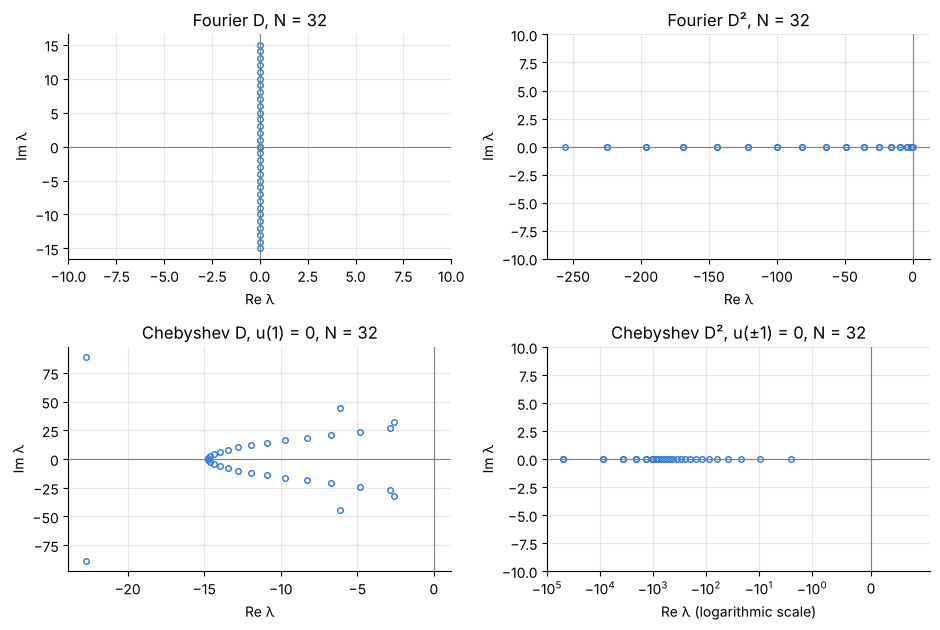

In [8]:
lam = spectra(32)
fig, axes = plt.subplots(2, 2, figsize=(9.5, 6.4))
for ax, (name, values) in zip(axes.flat, lam.items()):
    ax.plot(values.real, values.imag, "o", ms=4, mfc="none")
    ax.set(title=f"{name}, N = 32", xlabel="Re λ", ylabel="Im λ")
    ax.axhline(0, color="0.5", lw=0.8)
    ax.axvline(0, color="0.5", lw=0.8)
axes[0, 0].set(xlim=(-10, 10))
axes[0, 1].set(ylim=(-10, 10))
axes[1, 1].set_xscale("symlog", linthresh=1)                # the eigenvalues span four decades
axes[1, 1].set(xlim=(-1e5, 1), ylim=(-10, 10), xlabel="Re λ (logarithmic scale)")
fig.tight_layout()

The Fourier eigenvalues are evenly spaced on the imaginary axis (first derivative) or spread
along the negative real axis as $-k^2$ (second derivative). The Chebyshev first-derivative
matrix has complex eigenvalues in the left half-plane with modulus up to $0.089N^2$. The
Chebyshev second-derivative matrix has real negative eigenvalues: the ones near the origin
approximate $-(k\pi/2)^2$ (notebook 8), and the outliers reach $-0.048N^4$, which is $-50\,000$
for $N = 32$ on a problem whose slowest mode has $\lambda = -2.47$.

A caution from notebook 8: the Chebyshev first-derivative matrix is far from normal, and for
such matrices the eigenvalue rule is a guide, not a theorem. In practice a time step a little
below the eigenvalue limit works.

## 9.4 Time step limits

Put the two halves together. For a given formula, the largest stable step is the largest
$\Delta t$ for which all the $\lambda\,\Delta t$ fit inside its stability region.

In [9]:
def largest_stable_step(eigenvalues, R_of_z):
    """Largest Δt for which |R(λ Δt)| <= 1 for every eigenvalue λ (one-step formula with stability function R)."""
    excess = lambda dt: np.abs(R_of_z(dt * eigenvalues)).max() - 1 - 1e-9
    trial = np.geomspace(1e-8, 10, 4000)
    first_bad = np.argmax([excess(dt) > 0 for dt in trial])
    return brentq(excess, trial[first_bad - 1], trial[first_bad])

print("largest stable RK4 time step")
print("  N    Fourier D     Fourier D²    Chebyshev D   Chebyshev D²")
rk4_step_limit = {}
for N in (16, 32, 64):
    rk4_step_limit[N] = [largest_stable_step(values, R["RK4"]) for values in spectra(N).values()]
    print(f"{N:3d} " + "".join(f"{dt:14.2e}" for dt in rk4_step_limit[N]))
ratios = np.array(rk4_step_limit[32]) / np.array(rk4_step_limit[64])
print("32→64" + "".join(f"{ratio:11.1f}×  " for ratio in ratios))

largest stable RK4 time step
  N    Fourier D     Fourier D²    Chebyshev D   Chebyshev D²


 16       4.04e-01      4.35e-02      1.24e-01      8.77e-04


 32       1.89e-01      1.09e-02      3.17e-02      5.58e-05


 64       9.12e-02      2.72e-03      7.95e-03      3.50e-06
32→64        2.1×          4.0×          4.0×         15.9×  


In [10]:
# Verify the two Fourier columns against the formulas, and the scaling of all four
for N in (16, 32, 64):
    assert abs(rk4_step_limit[N][0] / (rk4_imag / (N / 2 - 1)) - 1) < 1e-3
    assert abs(rk4_step_limit[N][1] / (rk4_real / (N / 2) ** 2) - 1) < 1e-3
assert np.allclose(ratios, [2, 4, 4, 16], rtol=0.06)

Doubling $N$ divides the stable time step by 2, 4, 4 and 16:

| Problem | Grid | Largest eigenvalue | Explicit time step |
| --- | --- | --- | --- |
| advection, $u_t = u_x$ | Fourier | $N/2$ | $O(N^{-1})$ |
| diffusion, $u_t = u_{xx}$ | Fourier | $N^2/4$ | $O(N^{-2})$ |
| advection | Chebyshev | $0.089N^2$ | $O(N^{-2})$ |
| diffusion | Chebyshev | $0.048N^4$ | $O(N^{-4})$ |

The first line is the familiar condition that the wave may cross about one grid cell per step.
The last is severe: with $N = 64$ the heat equation on $[-1, 1]$ needs steps of
$3.5\times10^{-6}$ to follow a solution that changes on a time scale of order 1. A problem like
that, where stability demands a far smaller step than accuracy, is called **stiff**, and it is
where implicit formulas earn the cost of their linear solves.

## 9.5 Worked example: a pattern carried round a ring

**Problem.** A concentration pattern is carried at unit speed round a closed loop of length
$2\pi$ (a tracer in an annular channel, a temperature pattern on a rotating drum):

$$u_t + u_x = 0,\qquad u(x, 0) = e^{\sin x},\qquad u \text{ periodic}.$$

The exact solution is the initial pattern shifted, $u(x, t) = e^{\sin(x - t)}$. Solve with
the Fourier derivative in space and RK4 in time. How large can the time step be?

**By hand.** The eigenvalues of $-D$ are $-ik$ with $|k| \le N/2 - 1$, and RK4 is stable on the
imaginary axis up to $2.828$, so

$$\Delta t_{\max} = \frac{2.828}{N/2 - 1} .$$

In [11]:
def rk4_step(f, u, dt):
    """One step of the classical fourth-order Runge-Kutta formula for u' = f(u)."""
    k1 = f(u)
    k2 = f(u + dt / 2 * k1)
    k3 = f(u + dt / 2 * k2)
    k4 = f(u + dt * k3)
    return u + dt / 6 * (k1 + 2 * k2 + 2 * k3 + k4)

N = 64
x = 2 * np.pi * np.arange(N) / N
pattern = lambda x: np.exp(np.sin(x))
advection = lambda u: -fft_derivative(u)
dt_limit = rk4_imag / (N / 2 - 1)

def advect(dt, n_steps):
    """March n_steps from the initial pattern; returns the final state and the history of max |u|."""
    u, size = pattern(x), []
    for _ in range(n_steps):
        u = rk4_step(advection, u, dt)
        size.append(np.abs(u).max())
    return u, np.array(size)

history = {}
for factor in (0.95, 1.05):
    dt = factor * dt_limit
    history[factor] = (dt, advect(dt, int(20 / dt))[1])
    print(f"Δt = {factor:.2f} × limit = {dt:.4f}:  max |u| at t = 20 is {history[factor][1][-1]:.3e}")
growth = abs(R["RK4"](1.05j * rk4_imag))
print(f"growth factor per step of the highest mode at 1.05 × limit: {growth:.3f}")

Δt = 0.95 × limit = 0.0867:  max |u| at t = 20 is 2.718e+00
Δt = 1.05 × limit = 0.0958:  max |u| at t = 20 is 9.356e+14
growth factor per step of the highest mode at 1.05 × limit: 1.406


In [12]:
# Verify: stable just below the predicted limit, unstable just above
assert history[0.95][1].max() < np.e * (1 + 1e-6)             # the exact solution never exceeds e
assert history[1.05][1][-1] > 1e10

Five per cent below the limit the solution stays bounded by its exact maximum, $e$. Five per
cent above, the highest mode is multiplied by 1.41 at every step. It starts from a rounding
error of size $10^{-17}$ and has taken over completely by $t = 20$.

**Accuracy.** Stability is not accuracy. Measure the error after one trip round the ring,
$t = 2\pi$, as the time step is reduced.

measured order of accuracy in time: 3.999
error with 6400 steps: 1.2e-12


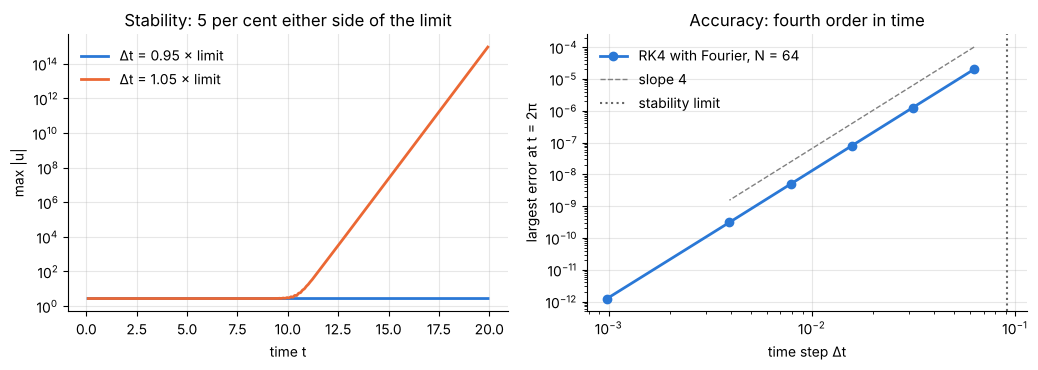

In [13]:
steps = np.array([100, 200, 400, 800, 1600, 6400])
errors = np.array([np.abs(advect(2 * np.pi / n, n)[0] - pattern(x)).max() for n in steps])
order = -np.polyfit(np.log(steps[:5]), np.log(errors[:5]), 1)[0]
print(f"measured order of accuracy in time: {order:.3f}")
print(f"error with 6400 steps: {errors[-1]:.1e}")
assert abs(order - 4) < 0.05 and errors[-1] < 1e-11            # fourth order in time; space error at rounding level

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8))
for factor, label in ((0.95, "Δt = 0.95 × limit"), (1.05, "Δt = 1.05 × limit")):
    dt, size = history[factor]
    axes[0].semilogy(dt * np.arange(1, len(size) + 1), size, label=label)
axes[0].set(xlabel="time t", ylabel="max |u|", title="Stability: 5 per cent either side of the limit")
axes[0].legend(frameon=False, loc="upper left")
axes[1].loglog(2 * np.pi / steps, errors, "o-", label="RK4 with Fourier, N = 64")
axes[1].loglog(2 * np.pi / steps[:5], 5 * errors[0] * (steps[0] / steps[:5]) ** 4.0, "--", color="0.5", lw=1, label="slope 4")
axes[1].axvline(dt_limit, color="0.4", ls=":", lw=1.5, label="stability limit")
axes[1].set(xlabel="time step Δt", ylabel="largest error at t = 2π", title="Accuracy: fourth order in time")
axes[1].legend(frameon=False, loc="upper left")
fig.tight_layout()

The error falls as $\Delta t^4$ down to $10^{-12}$, so the whole error is the time-stepping
error: with 64 points the space discretization is exact to rounding. At the largest stable
step the error is about $10^{-4}$. This is the typical situation for wave problems with
spectral methods: the stability limit and the accuracy requirement ask for similar time steps,
and an explicit formula is the right tool.

## 9.6 Worked example: cooling of a slab, explicit against implicit

**Problem.** A slab occupies $-1 \le x \le 1$ (lengths in units of the half-thickness $a$, time
in units of $a^2/\alpha$ with $\alpha$ the thermal diffusivity). Its surfaces are held at
temperature zero and the initial temperature is $\cos(\pi x/2) + \tfrac14\cos(3\pi x/2)$:

$$u_t = u_{xx},\qquad u(\pm1, t) = 0 .$$

Find the temperature up to $t = 1$.

**By hand.** Each cosine is an eigenfunction of the model problem of notebook 8, with
eigenvalues $-\pi^2/4$ and $-9\pi^2/4$, so the exact solution is

$$u(x, t) = e^{-\pi^2 t/4}\cos\frac{\pi x}{2} + \tfrac14\,e^{-9\pi^2 t/4}\cos\frac{3\pi x}{2} .$$

The second term dies nine times faster and the slab soon cools in its lowest mode, at the
rate $\pi^2/4 = 2.47$. An accurate solution needs time steps that are a fraction of $1/2.47$.
Stability of an explicit formula needs far smaller ones: with $N = 24$ the largest eigenvalue
is $-0.048N^4 \approx -16\,000$, so RK4 is limited to $\Delta t < 2.785/16\,000$.

The trapezoidal rule has no such limit. Applied to $\mathbf{u}' = A\mathbf{u}$ it reads

$$\big(I - \tfrac12\Delta t\,A\big)\,\mathbf{u}^{n+1} = \big(I + \tfrac12\Delta t\,A\big)\,\mathbf{u}^n ,$$

known for the heat equation as the **Crank-Nicolson** method. The matrix on the left is the
same at every step, so it is factorized once.

In [14]:
N = 24
D, x_all = cheb(N)
A, x = (D @ D)[1:-1, 1:-1], x_all[1:-1]                      # interior unknowns; u = 0 at index 0 (x = 1) and index N (x = -1)
slab_exact = lambda x, t: (np.exp(-np.pi**2 * t / 4) * np.cos(np.pi * x / 2)
                           + 0.25 * np.exp(-9 * np.pi**2 * t / 4) * np.cos(3 * np.pi * x / 2))
t_end, centre = 1.0, N // 2 - 1                              # the interior index of x = 0
dt_rk4 = largest_stable_step(np.linalg.eigvals(A), R["RK4"])

def slab_rk4(dt_target, blow_up=1e6):
    """Explicit RK4 to t_end; stops early if the solution exceeds blow_up. Returns u, times, centre values."""
    n = int(np.ceil(t_end / dt_target))
    dt, u, centre_values = t_end / n, slab_exact(x, 0), []
    for _ in range(n):
        u = rk4_step(lambda v: A @ v, u, dt)
        centre_values.append(u[centre])
        if np.abs(u).max() > blow_up:
            break
    return u, dt * np.arange(1, len(centre_values) + 1), np.array(centre_values)

def slab_trapezoidal(dt_target):
    """Crank-Nicolson to t_end. Returns u, times, centre values."""
    n = int(np.ceil(t_end / dt_target))
    dt, u, centre_values = t_end / n, slab_exact(x, 0), []
    I = np.eye(N - 1)
    factors, right = lu_factor(I - dt / 2 * A), I + dt / 2 * A
    for _ in range(n):
        u = lu_solve(factors, right @ u)
        centre_values.append(u[centre])
    return u, dt * np.arange(1, n + 1), np.array(centre_values)

u_rk4, t_rk4, c_rk4 = slab_rk4(0.95 * dt_rk4)
u_bad, t_bad, _ = slab_rk4(1.05 * dt_rk4)
u_cn, t_cn, c_cn = slab_trapezoidal(100 * dt_rk4)
u_cn_huge = slab_trapezoidal(10000 * dt_rk4)[0]

scale = np.abs(slab_exact(x, t_end)).max()
print(f"RK4 stability limit: Δt = {dt_rk4:.3e}")
print(f"RK4 at 0.95 × limit:   {len(t_rk4):5d} steps, relative error at t = 1: {np.abs(u_rk4 - slab_exact(x, t_end)).max() / scale:.1e}")
print(f"RK4 at 1.05 × limit:   exceeds 10⁶ after {len(t_bad)} steps (t = {t_bad[-1]:.3f})")
print(f"trapezoidal, 100 × limit: {len(t_cn):3d} steps, relative error at t = 1: {np.abs(u_cn - slab_exact(x, t_end)).max() / scale:.1e}")
print(f"trapezoidal, 10000 × limit: {int(np.ceil(t_end / (10000 * dt_rk4)))} step,  max |u| = {np.abs(u_cn_huge).max():.3f}")

RK4 stability limit: Δt = 1.755e-04
RK4 at 0.95 × limit:    5998 steps, relative error at t = 1: 1.6e-14
RK4 at 1.05 × limit:   exceeds 10⁶ after 248 steps (t = 0.046)
trapezoidal, 100 × limit:  57 steps, relative error at t = 1: 3.9e-04
trapezoidal, 10000 × limit: 1 step,  max |u| = 0.313


decay rate of the centre temperature for t > 0.7: 2.46740166   π²/4 = 2.46740110


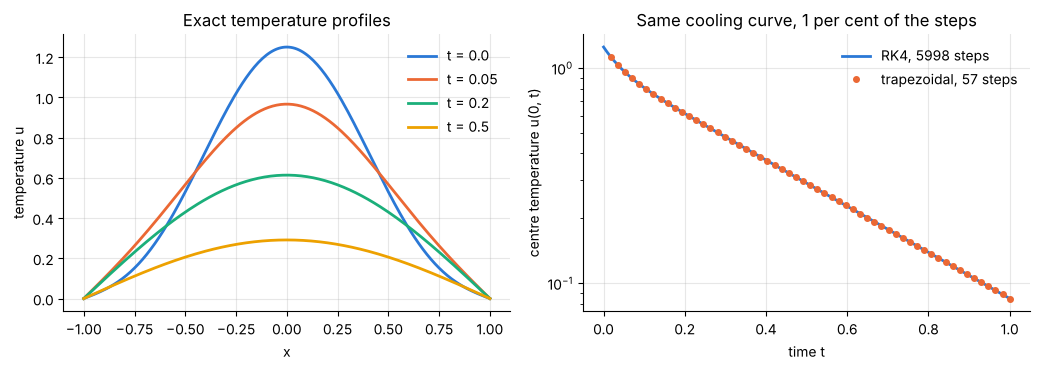

In [15]:
# Verify: the stability statements, the accuracy of both, and the decay rate π²/4 measured from the RK4 run
assert np.abs(u_bad).max() > 1e6 and len(t_bad) < len(t_rk4)                  # RK4 just above its limit blows up
assert np.abs(u_rk4 - slab_exact(x, t_end)).max() < 1e-12                     # RK4 just below it is accurate
assert np.abs(u_cn - slab_exact(x, t_end)).max() / scale < 1e-3               # trapezoidal with 100 times the step
assert np.abs(u_cn_huge).max() < 1.5 and len(t_cn) * 100 <= len(t_rk4) + 100  # still bounded with one giant step
late = t_rk4 > 0.7
decay_rate = -np.polyfit(t_rk4[late], np.log(c_rk4[late]), 1)[0]
print(f"decay rate of the centre temperature for t > 0.7: {decay_rate:.8f}   π²/4 = {np.pi**2 / 4:.8f}")
assert abs(decay_rate - np.pi**2 / 4) < 1e-5

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8))
fine = np.linspace(-1, 1, 201)
for t_plot, colour in zip((0.0, 0.05, 0.2, 0.5), (BLUE, ORANGE, GREEN, "#eda100")):
    axes[0].plot(fine, slab_exact(fine, t_plot), color=colour, label=f"t = {t_plot}")
axes[0].set(xlabel="x", ylabel="temperature u", title="Exact temperature profiles")
axes[0].legend(frameon=False, loc="upper right")
axes[1].semilogy(t_rk4, c_rk4, label=f"RK4, {len(t_rk4)} steps")
axes[1].semilogy(t_cn, c_cn, "o", ms=4, label=f"trapezoidal, {len(t_cn)} steps")
axes[1].set(xlabel="time t", ylabel="centre temperature u(0, t)", title="Same cooling curve, 1 per cent of the steps")
axes[1].legend(frameon=False, loc="upper right")
fig.tight_layout()

RK4 needs 5998 steps to reach $t = 1$, and five per cent above its limit it fails within a
few hundred steps. Its result is accurate to rounding error, far more than anyone asked for:
the step was dictated by stability alone. The trapezoidal rule takes 57 steps, each 100 times
longer, and its relative error is $4\times10^{-4}$, ample for a temperature. The two are not
equally accurate, but the implicit formula lets accuracy choose the step, and here that saves
a factor of 100 in steps. It remains bounded even with a single step of length 1.

In physical terms, for a steel plate 2 cm thick ($a = 1$ cm, $\alpha = 1.2\times10^{-5}$ m²/s)
the time unit is 8.3 s and the cooling time constant $4/\pi^2$ units, or 3.4 s. Explicit RK4
with 25 Chebyshev points would have to take steps of 1.4 ms.

One caution about the trapezoidal rule. For very large $|z|$ its factor $R(z)$ tends to $-1$,
so modes with huge eigenvalues are not damped but flip sign at every step. With smooth data, as
here, they are never excited. With rough data, use smaller steps at first or a formula such as
backward Euler, whose $R(z)$ tends to zero.

## 9.7 Worked example: a pulse on a cable with a heavy section

**Problem.** A taut cable under unit tension forms a closed loop of length $2\pi$ (periodic
grid). Transverse waves travel along it at the speed $c = 1/\sqrt{\rho}$, where $\rho$ is the
mass per unit length. Near $x = 3.6$ the cable is four times heavier, so the wave speed drops
smoothly from 1 to $\tfrac12$:

$$u_{tt} = c(x)^2\,u_{xx},\qquad c(x) = 1 - \tfrac12\exp\!\big(-8\,(1 - \cos(x - 3.6))\big) .$$

A pulse $u = e^{-((x - 1.2)/0.15)^2}$ is launched to the right at $t = 0$. Where is it at
$t = 4.5$, and how much is reflected by the heavy section?

**By hand.** A pulse moves at the local wave speed, $dx/dt = c(x)$, so the time to travel from
$x_0$ to $X$ is $\int_{x_0}^{X} dx/c(x)$. Setting this equal to 4.5 predicts the position $X$.
The second check is energy: $E = \tfrac12\int\big(u_t^2/c^2 + u_x^2\big)\,dx$ is conserved.

For the time stepping, write the equation as a first-order system for $u$ and $v = u_t$:

$$u_t = v,\qquad v_t = c^2 u_{xx} .$$

Its eigenvalues are purely imaginary, $\pm i\sqrt{\mu}$ with $-\mu$ an eigenvalue of
$c^2 D^{(2)}$, and they are bounded by $c_{\max}N/2$. Purely imaginary eigenvalues are what
leapfrog is made for: it is stable when $|\lambda|\Delta t < 1$, costs one evaluation of the
right-hand side per step, and neither amplifies nor damps any mode. It needs two starting
levels; the first step is taken with RK4.

In [16]:
N = 256
x = 2 * np.pi * np.arange(N) / N
speed = lambda x: 1 - 0.5 * np.exp(-8 * (1 - np.cos(x - 3.6)))
c = speed(x)
x_start, t_end = 1.2, 4.5
u0 = np.exp(-((x - x_start) / 0.15) ** 2)
v0 = -fft_derivative(u0)                                     # a right-moving pulse where c = 1: u_t = -u_x

wave_rhs = lambda w: np.array([w[1], c**2 * fft_derivative(w[0], 2)])
wave_energy = lambda w: 0.5 * np.sum(w[1] ** 2 / c**2 + fft_derivative(w[0]) ** 2) * 2 * np.pi / N

def leapfrog(dt_target, n_max=None):
    """Leapfrog for the cable; returns the final state, the energy history and snapshots of u."""
    n = int(np.ceil(t_end / dt_target))
    dt = t_end / n
    old = np.array([u0, v0])
    new = rk4_step(wave_rhs, old, dt)                        # starting step
    energy, snapshots = [wave_energy(old), wave_energy(new)], [u0, new[0]]
    for _ in range((n_max or n) - 1):
        old, new = new, old + 2 * dt * wave_rhs(new)
        energy.append(wave_energy(new))
        snapshots.append(new[0])
    return new, np.array(energy), np.array(snapshots), dt

dt_leapfrog = 1 / (c.max() * N / 2)
state, energy, snapshots, dt = leapfrog(0.5 * dt_leapfrog)
unstable_energy = leapfrog(1.05 * dt_leapfrog, n_max=300)[1]

# predicted position: invert the travel time, integrated on a fine grid with the trapezoidal rule
s = np.linspace(x_start, 2 * np.pi, 200001)
travel_time = np.concatenate([[0], np.cumsum((1 / speed(s[1:]) + 1 / speed(s[:-1])) / 2 * np.diff(s))])
x_predicted = np.interp(t_end, travel_time, s)

# measured position: the peak of the trigonometric interpolant on a grid 16 times finer
padded = np.zeros(16 * N, dtype=complex)
u_hat = np.fft.fft(state[0])
padded[:N // 2], padded[-N // 2:] = u_hat[:N // 2], u_hat[N // 2:]
u_fine = 16 * np.real(np.fft.ifft(padded))
x_measured = 2 * np.pi * np.argmax(u_fine) / (16 * N)

print(f"leapfrog limit Δt = {dt_leapfrog:.5f};  used Δt = {dt:.5f}, {len(energy) - 1} steps")
print(f"pulse position at t = {t_end}:  measured {x_measured:.4f}   predicted {x_predicted:.4f}   (at unit speed it would be {x_start + t_end:.1f})")
print(f"largest relative change of the energy: {np.abs(energy / energy[0] - 1).max():.1e}")
print(f"transmitted pulse height {u_fine.max():.3f}, reflected pulse height {u_fine.min():.3f}")

leapfrog limit Δt = 0.00781;  used Δt = 0.00391, 1152 steps
pulse position at t = 4.5:  measured 4.9808   predicted 4.9764   (at unit speed it would be 5.7)
largest relative change of the energy: 1.9e-05
transmitted pulse height 0.985, reflected pulse height -0.055


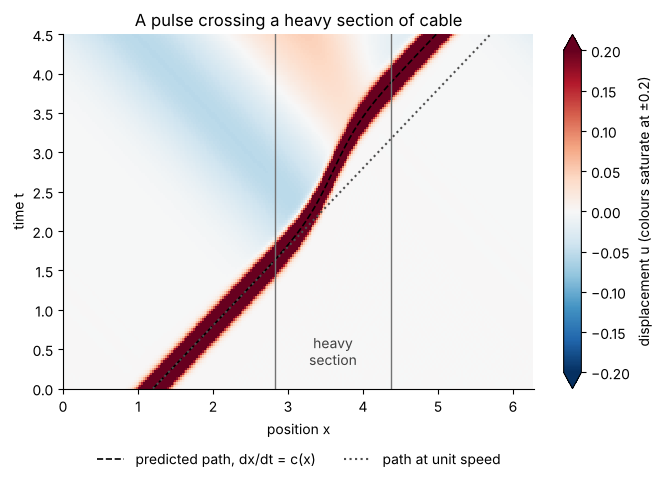

In [17]:
# Verify: travel time, energy conservation, and the leapfrog stability limit
assert abs(x_measured - x_predicted) < 0.01 and x_start + t_end - x_measured > 0.7
assert np.abs(energy / energy[0] - 1).max() < 1e-4
assert unstable_energy[-1] > 1e6 * unstable_energy[0]

fig, ax = plt.subplots(figsize=(7.6, 4.6))
every = 8
image = ax.pcolormesh(x, dt * np.arange(0, len(snapshots), every), snapshots[::every], cmap="RdBu_r", vmin=-0.2, vmax=0.2, shading="auto")
ax.plot(s[travel_time <= t_end], travel_time[travel_time <= t_end], "k--", lw=1.2, label="predicted path, dx/dt = c(x)")
ax.plot([x_start, x_start + t_end], [0, t_end], ":", color="0.3", lw=1.5, label="path at unit speed")
heavy = x[c < 0.95]
for edge in (heavy[0], heavy[-1]):
    ax.axvline(edge, color="0.45", lw=1)
ax.annotate("heavy\nsection", xy=(3.6, 0.3), ha="center", color="0.25")
ax.set(xlabel="position x", ylabel="time t", xlim=(0, 2 * np.pi), ylim=(0, t_end), title="A pulse crossing a heavy section of cable")
ax.grid(False)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2)
fig.colorbar(image, label="displacement u (colours saturate at ±0.2)", extend="both");

The pulse slows down in the heavy section, where its path in the $x$-$t$ plane steepens, and
emerges 0.72 behind where it would have been at unit speed, within 0.005 of the position
predicted from the travel-time integral. Part of the pulse is reflected: a weak negative
pulse from the entry to the heavy section (the blue band running back to the left; the colour
scale is chosen to show it) and a weaker positive one from the exit. A change in wave speed
acts as a partial mirror, which is the principle of time-domain reflectometry for locating
faults and joints in cables. The energy is constant to two parts in $10^{5}$ over 1152 steps,
and five per cent above the leapfrog limit it grows by more than a factor $10^6$ in 300 steps.

## Summary

- Method of lines: discretize space, then integrate $\mathbf{u}' = L_N\mathbf{u}$ in time. Rule
  of thumb: every $\lambda\,\Delta t$ must lie in the stability region of the formula.
- RK4 is stable to 2.785 on the negative real axis and to $2.828i$ on the imaginary axis.
  Forward Euler is useless for undamped waves, and RK2 and AB2 are unsuitable for long runs;
  leapfrog covers $(-i, i)$.
- Spectral matrices have large eigenvalues: $N/2$ and $N^2/4$ for Fourier first and second
  derivatives, $0.089N^2$ and $0.048N^4$ for Chebyshev, because of the $O(N^{-2})$ grid spacing
  at the ends.
- Explicit steps are therefore $O(N^{-1})$ for periodic waves, where they are a good choice,
  and $O(N^{-4})$ for Chebyshev diffusion, where an implicit formula such as the trapezoidal
  rule is far cheaper.
- Check stability and accuracy separately: one is about the largest eigenvalues, the other
  about the modes that carry the solution.

When the stiff part of a problem is linear and the rest is nonlinear, it is not necessary to
make the whole scheme implicit. Integrating-factor and exponential time-differencing methods
treat the linear part exactly and remove the worst restriction. Notebook 11 uses them for
nonlinear waves.

## Exercises

1. The third-order Runge-Kutta formulas have $R(z) = 1 + z + \tfrac12 z^2 + \tfrac16 z^3$.
   Compute how far the stability region extends along the negative real axis and along the
   imaginary axis (exact value on the imaginary axis: $\sqrt3$). Add the region to the first
   panel of the figure in 9.2. Per evaluation of the right-hand side, is RK3 or RK4 the more
   economical choice for the advection problem of 9.5?
2. Use the boundary-locus method to plot the stability region of the second-order backward
   differentiation formula (BDF2), $\tfrac32u^{n+1} - 2u^n + \tfrac12u^{n-1} = \Delta t\,f^{n+1}$.
   Show that the locus crosses the real axis at $z = 0$ and $z = 4$, decide with a root test at
   $z = -1$ and $z = 1$ on which side the formula is stable, and find $|\zeta|$ of the larger
   root as $z \to -\infty$. Why is BDF2 often preferred to the trapezoidal rule for the heat
   equation with rough initial data?
3. Solve $u_t + u_x = 0$ on $[-1, 1]$ with the inflow condition $u(-1, t) = 0$, the initial
   pulse $u(x, 0) = e^{-40(x + 0.3)^2}$, Chebyshev points with $N = 48$ and RK4, up to $t = 0.8$.
   (The wave moves to the right, so the boundary value is prescribed at index $N$.) Compute the
   largest stable RK4 step from the eigenvalues, run at 0.9 and 1.2 times that step, and
   compare the stable run with the exact solution $e^{-40(x - t + 0.3)^2}$.
4. Repeat the cooling problem of 9.6 with $N = 48$. By what factor does the RK4 step limit
   change, and how many RK4 steps are now needed to reach $t = 1$? Run the trapezoidal rule
   with 50, 100, 200 and 400 steps, confirm that its error at $t = 1$ falls as $\Delta t^2$,
   and state how many steps give a relative error below $10^{-5}$.
5. In the cable problem of 9.7 make the heavy section sixteen times heavier, so that the
   minimum wave speed is $\tfrac14$: $c(x) = 1 - \tfrac34\exp(-8(1 - \cos(x - 3.6)))$. Predict the
   position of the transmitted pulse at $t = 5.5$ from the travel-time integral and compare it
   with the leapfrog solution ($N = 256$, half the limiting step). How large is the reflected pulse
   now, and is the energy still conserved to $10^{-4}$?